In [57]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist20mona23v3/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,res,ace,nce,prec_mz,peaks,ri,group_id
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,2,8.0,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,2,10.0,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,2,14.0,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,2,16.0,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,2,20.0,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0


In [58]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist20_hr'])]
nist_spectra_df.shape

(1005897, 17)

In [59]:
nist_spectra_df.loc[:, 'ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500 if pd.isnull(x['ace']) else x['ace'] , 0), axis=1)
nist_spectra_df.loc[:, 'nce'] = nist_spectra_df.apply(lambda x: round(x['ace'] * 500 / x['prec_mz'] if pd.isnull(x['nce']) else x['nce'] , 0), axis=1)

In [60]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = nist_spectra_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 6091

Top adduct types:

prec_type
[M+H]+                       311072
[M-H]-                       123854
[M+H-H2O]+                    84118
[M+Na]+                       38337
[2M+H]+                       28761
                              ...  
[M+H-CH6O2-C2H6O3-CO]+            1
[M+H-CH6O2-CH4O2-C4H4O2]+         1
[M+H-CH6O2-H2O]+                  1
[M-H-C4H8O4-CH4O]-                1
[M+H-C5H8O2-C5H10O2]+             1
Name: count, Length: 6091, dtype: int64


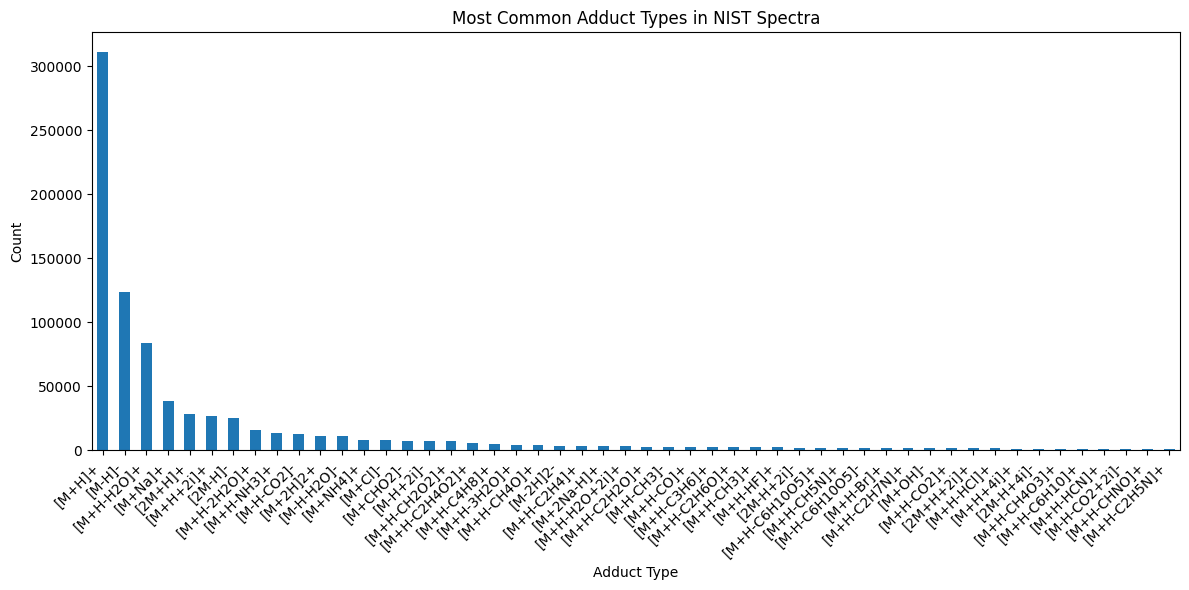

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

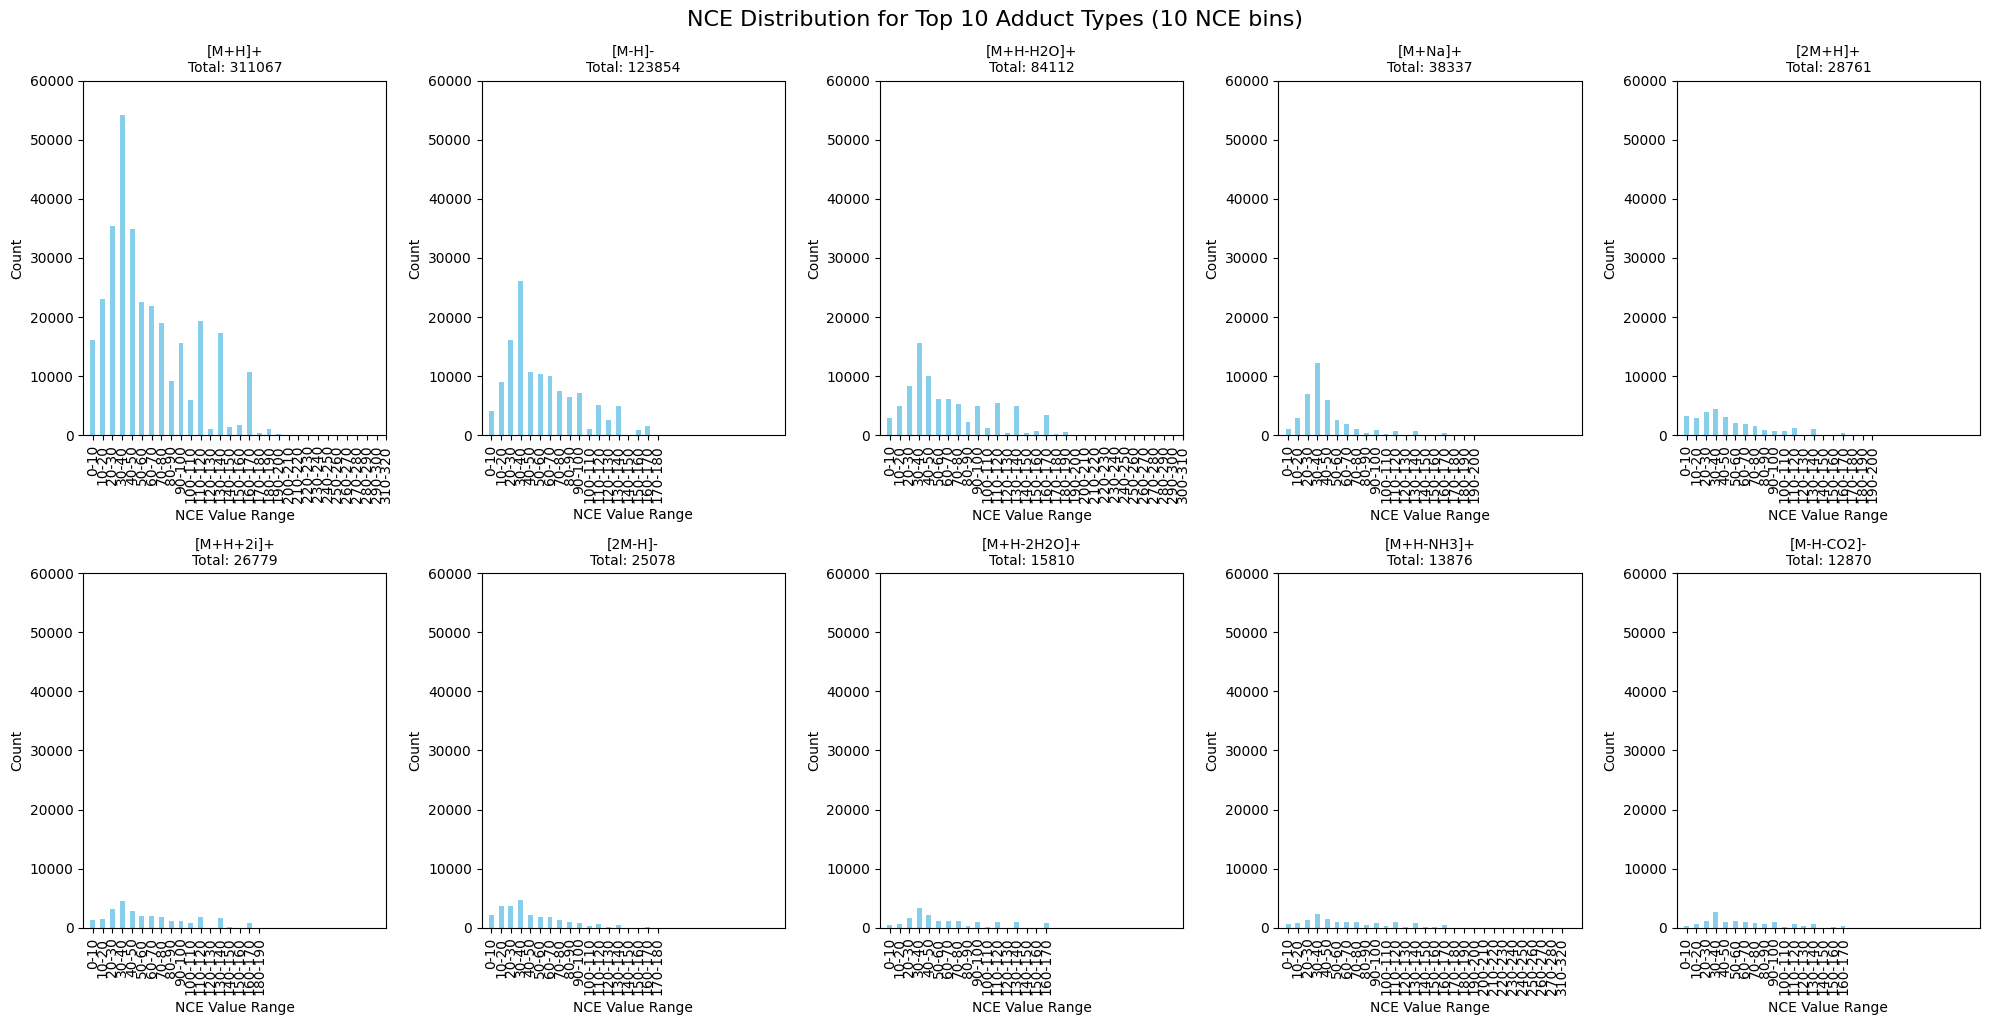

In [62]:
import numpy as np

prec_type_nce_counts = nist_spectra_df.groupby(['prec_type', 'nce']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_nce_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define NCE bins
nce_bin_size = 10
bins = np.arange(0, 325, nce_bin_size)
bin_labels = [f"{b}-{b+nce_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_nce_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('NCE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 60_000)
    
    ax.set_xlim(-1, 30)
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'NCE Distribution for Top 10 Adduct Types ({nce_bin_size} NCE bins)', fontsize=16, y=1.02)
plt.show()

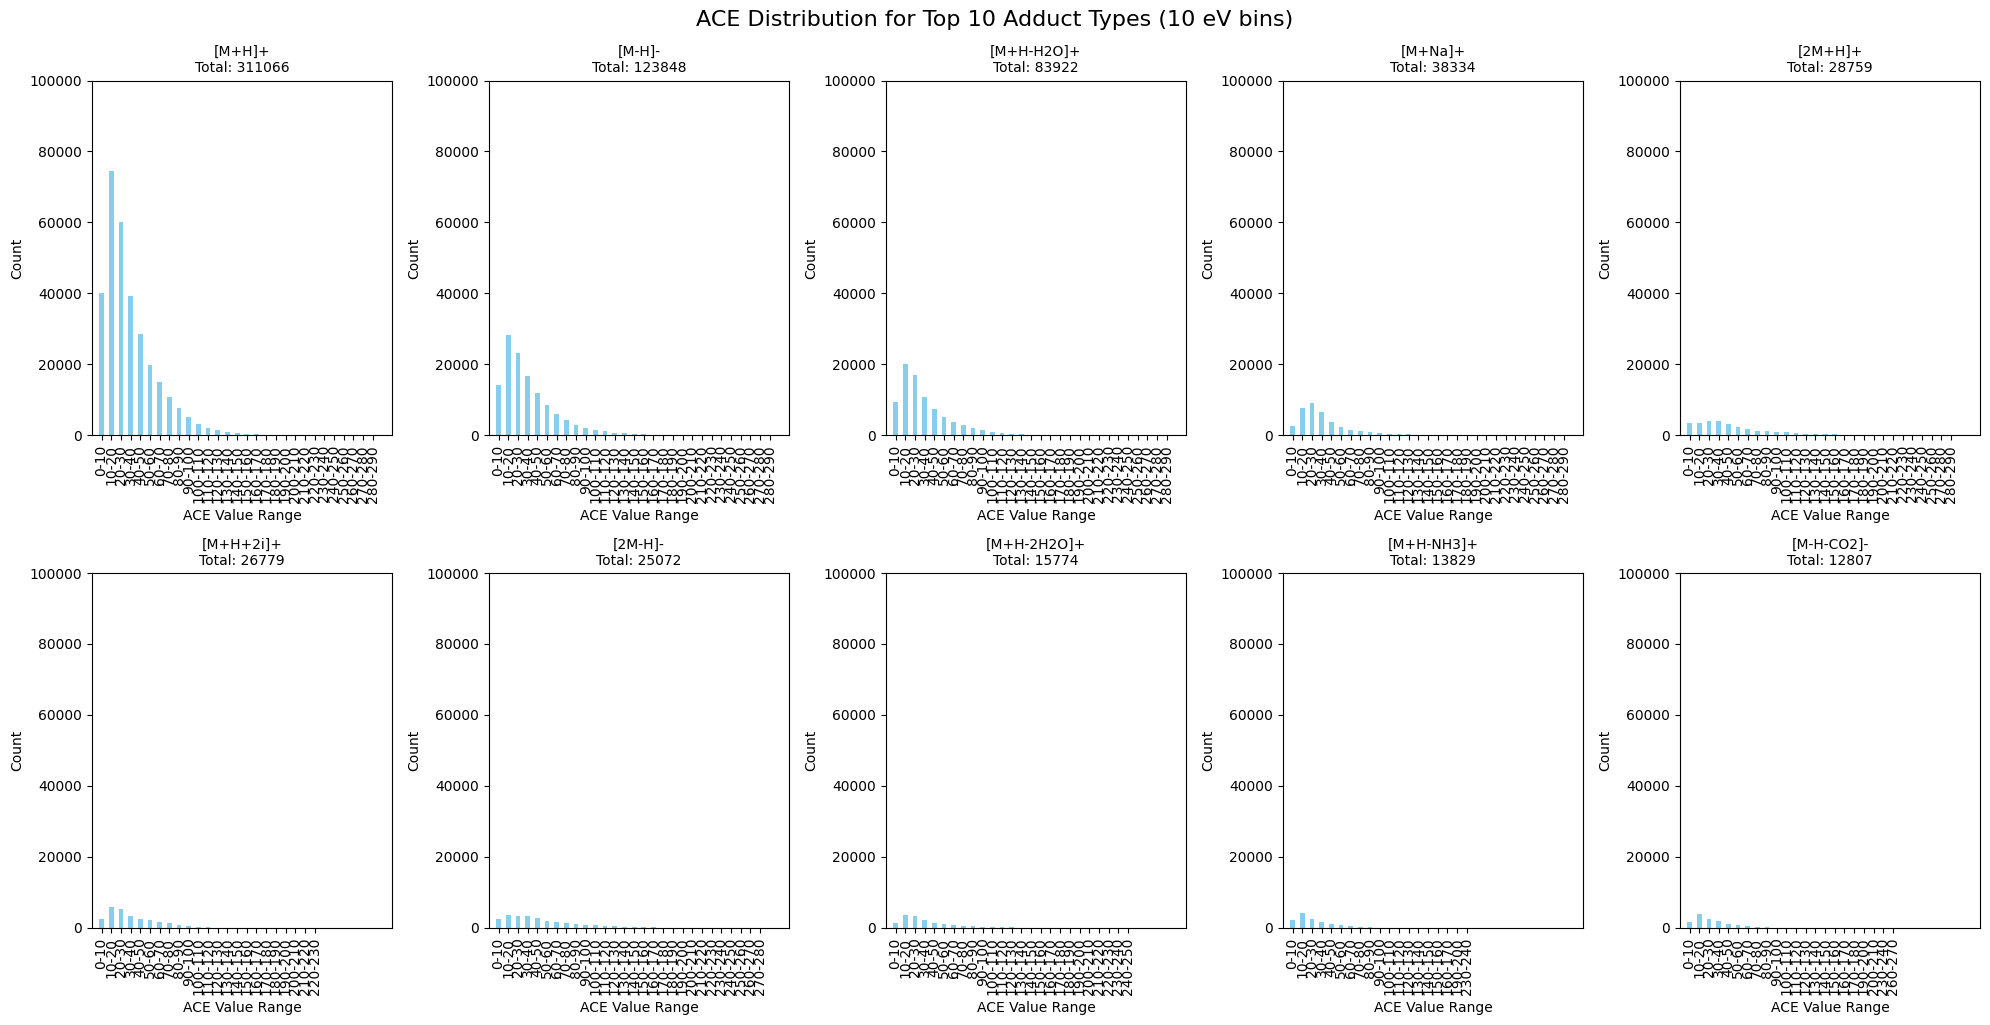

In [63]:
import numpy as np

prec_type_ace_counts = nist_spectra_df.groupby(['prec_type', 'ace']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_ace_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(10).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(2, 5, figsize=(20, 10), sharey=False)
axes = axes.flatten()

# Define ACE bins
ace_bin_size = 10
bins = np.arange(0, 300, ace_bin_size)
bin_labels = [f"{b}-{b+ace_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_ace_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('ACE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 100_000)
    
    ax.set_xlim(-1, 30)
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'ACE Distribution for Top 10 Adduct Types ({ace_bin_size} eV bins)', fontsize=16, y=1.02)
plt.show()

In [64]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20mona23v3/mol_df.pkl')
nist_mol_df.drop(['mol'], axis=1, inplace=True)
nist_mol_df.head()

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [65]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')
nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0


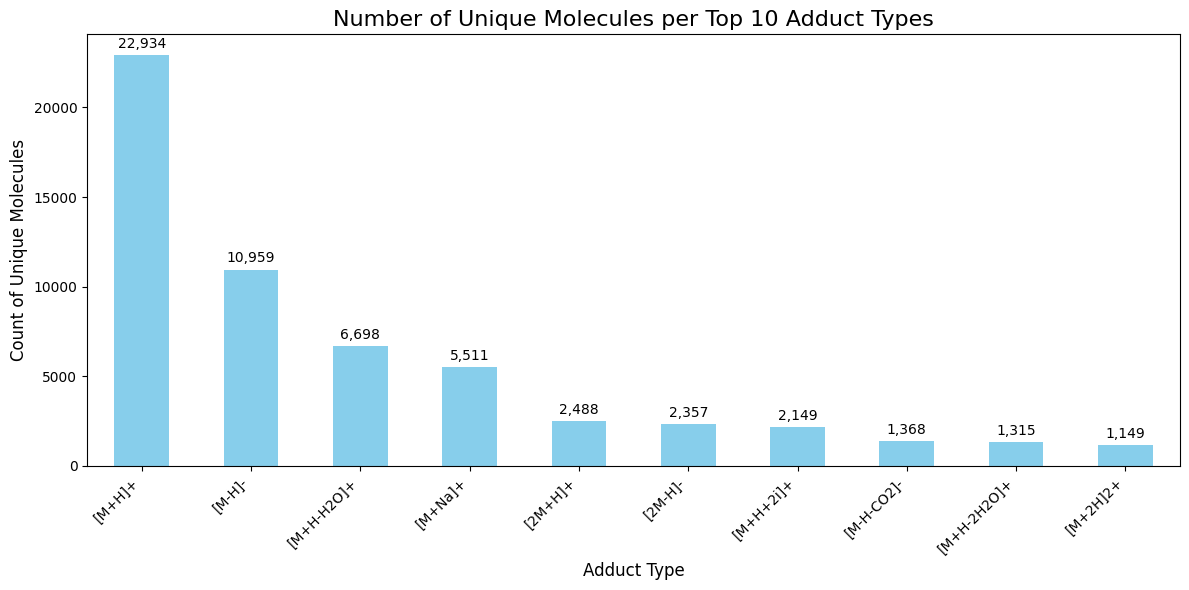

Number of unique molecules per adduct type:
prec_type
[M+H]+         22934
[M-H]-         10959
[M+H-H2O]+      6698
[M+Na]+         5511
[2M+H]+         2488
[2M-H]-         2357
[M+H+2i]+       2149
[M-H-CO2]-      1368
[M+H-2H2O]+     1315
[M+2H]2+        1149
Name: mol_id, dtype: int64


In [66]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(10)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 10 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)

In [67]:
frag_dp = '../../data/frag/nist20mona23v2_d4_h4_isoFalse_nb3'
spec_frag_stats_df = pd.read_pickle(f'{frag_dp}/spec_stats_df.pkl')
spec_frag_stats_df = spec_frag_stats_df.merge(nist_df[['spec_id', 'prec_type','ace','nce']], on='spec_id', how='left')
spec_frag_stats_df.head()

,spec_id,mol_id,recall_0.01_h1,wrecall_0.01_h1,prec_0.01_h1,ppt_peak_0.01_h1,ppt_formula_0.01_h1,prec_recall_0.01_h1,prec_spec_recall_0.01_h1,recall_0.01_h2,...,num_formulae,depth,formula_redundancy,dag_num_edges,dag_num_nodes,dag_sparsity,dag_num_nodes_nb,prec_type,ace,nce
0,274875,11520,0.222222,0.336657,0.001422,1.0,1.0,1.0,1.0,0.444444,...,5956,4,38.854768,502862,25983,0.00149,14863,[M+H]+,23.0,15.0
1,274876,11520,0.153846,0.109913,0.001422,1.0,1.0,1.0,1.0,0.461538,...,5956,4,38.854768,502862,25983,0.00149,14863,[M+H]+,31.0,20.0
2,274877,11520,0.250000,0.021010,0.002134,1.0,1.0,1.0,1.0,0.583333,...,5956,4,38.854768,502862,25983,0.00149,14863,[M+H]+,39.0,25.0
3,274878,11520,0.214286,0.014022,0.002134,1.0,1.0,1.0,1.0,0.571429,...,5956,4,38.854768,502862,25983,0.00149,14863,[M+H]+,47.0,30.0
4,274879,11520,0.200000,0.025013,0.002134,1.0,1.0,1.0,0.0,0.533333,...,5956,4,38.854768,502862,25983,0.00149,14863,[M+H]+,55.0,35.0


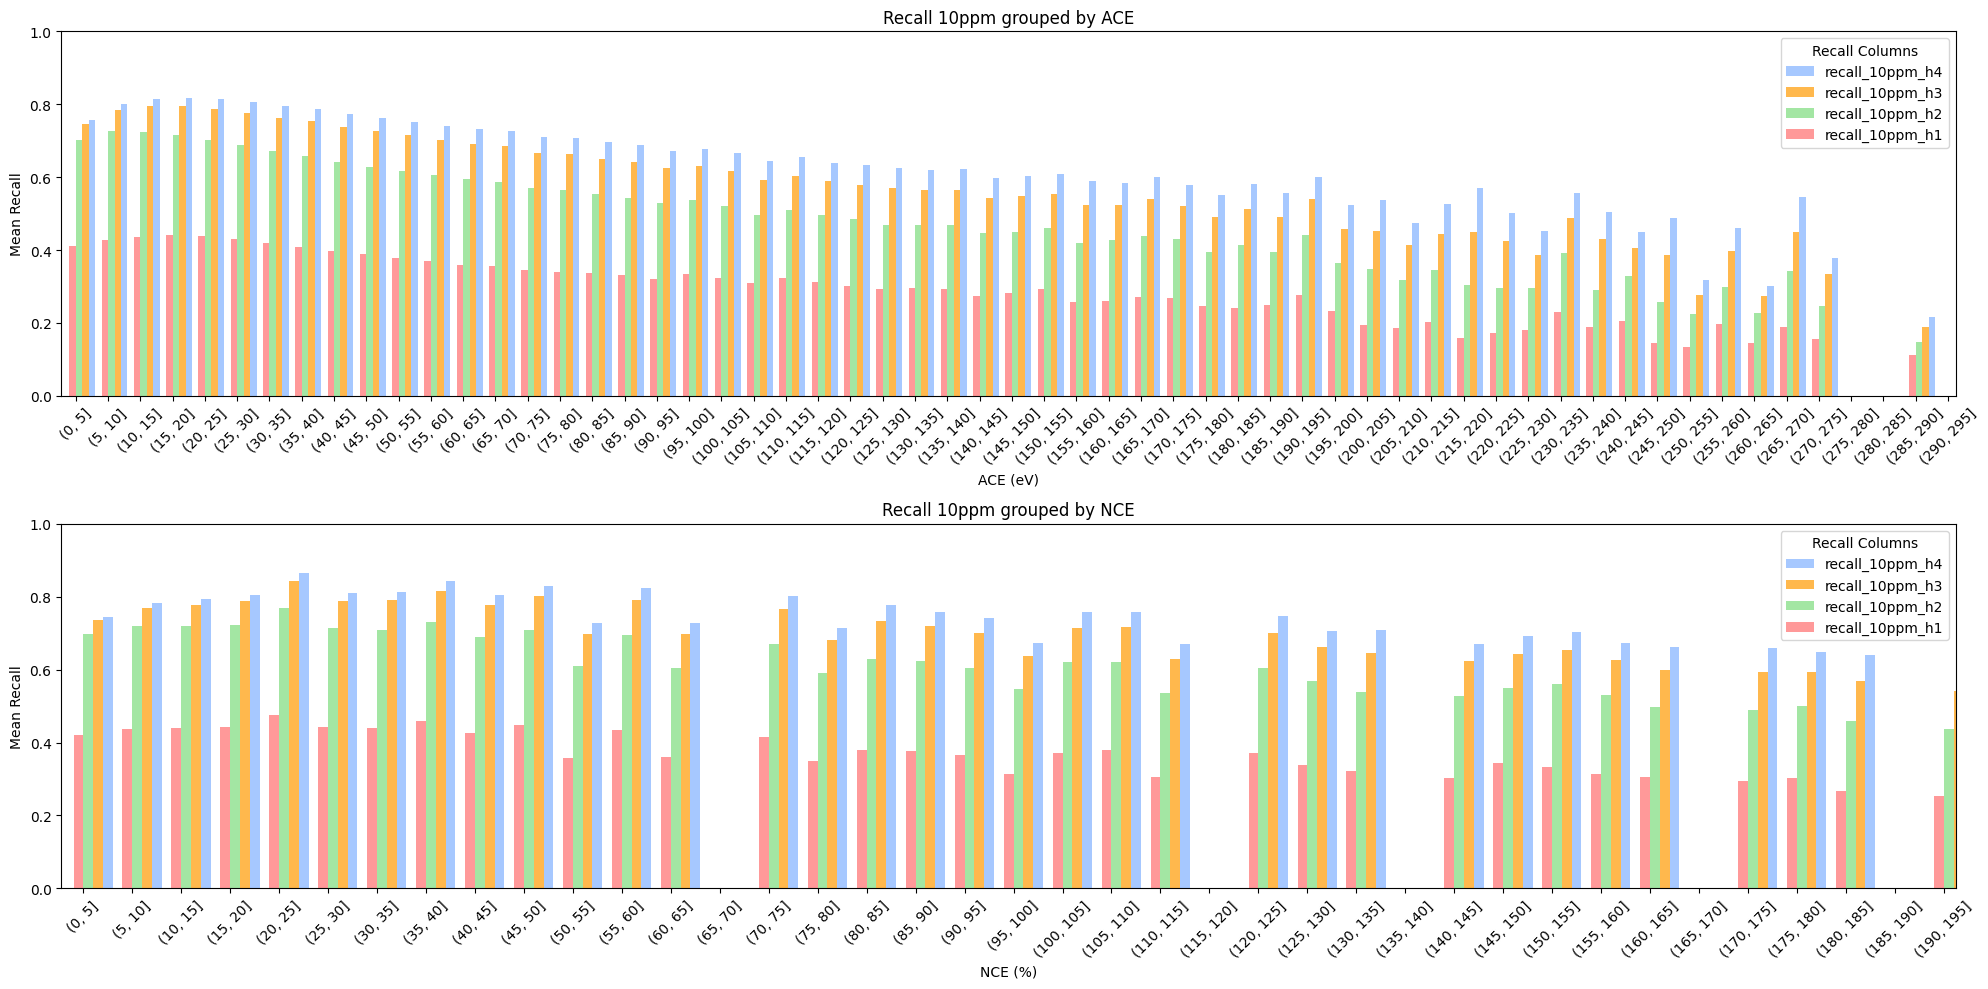

In [68]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']
recall_columns.reverse()

# Define ACE and NCE bins
ace_bin_size = 5
nce_bin_size = 5
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
axes = axes.flatten()

# New color choices (You can use color names, hex values, or RGB tuples)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot histograms for each recall column grouped by ACE
ax = axes[0]
width = 0.2  # Bar width for separation
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot histograms for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['nce'], nce_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

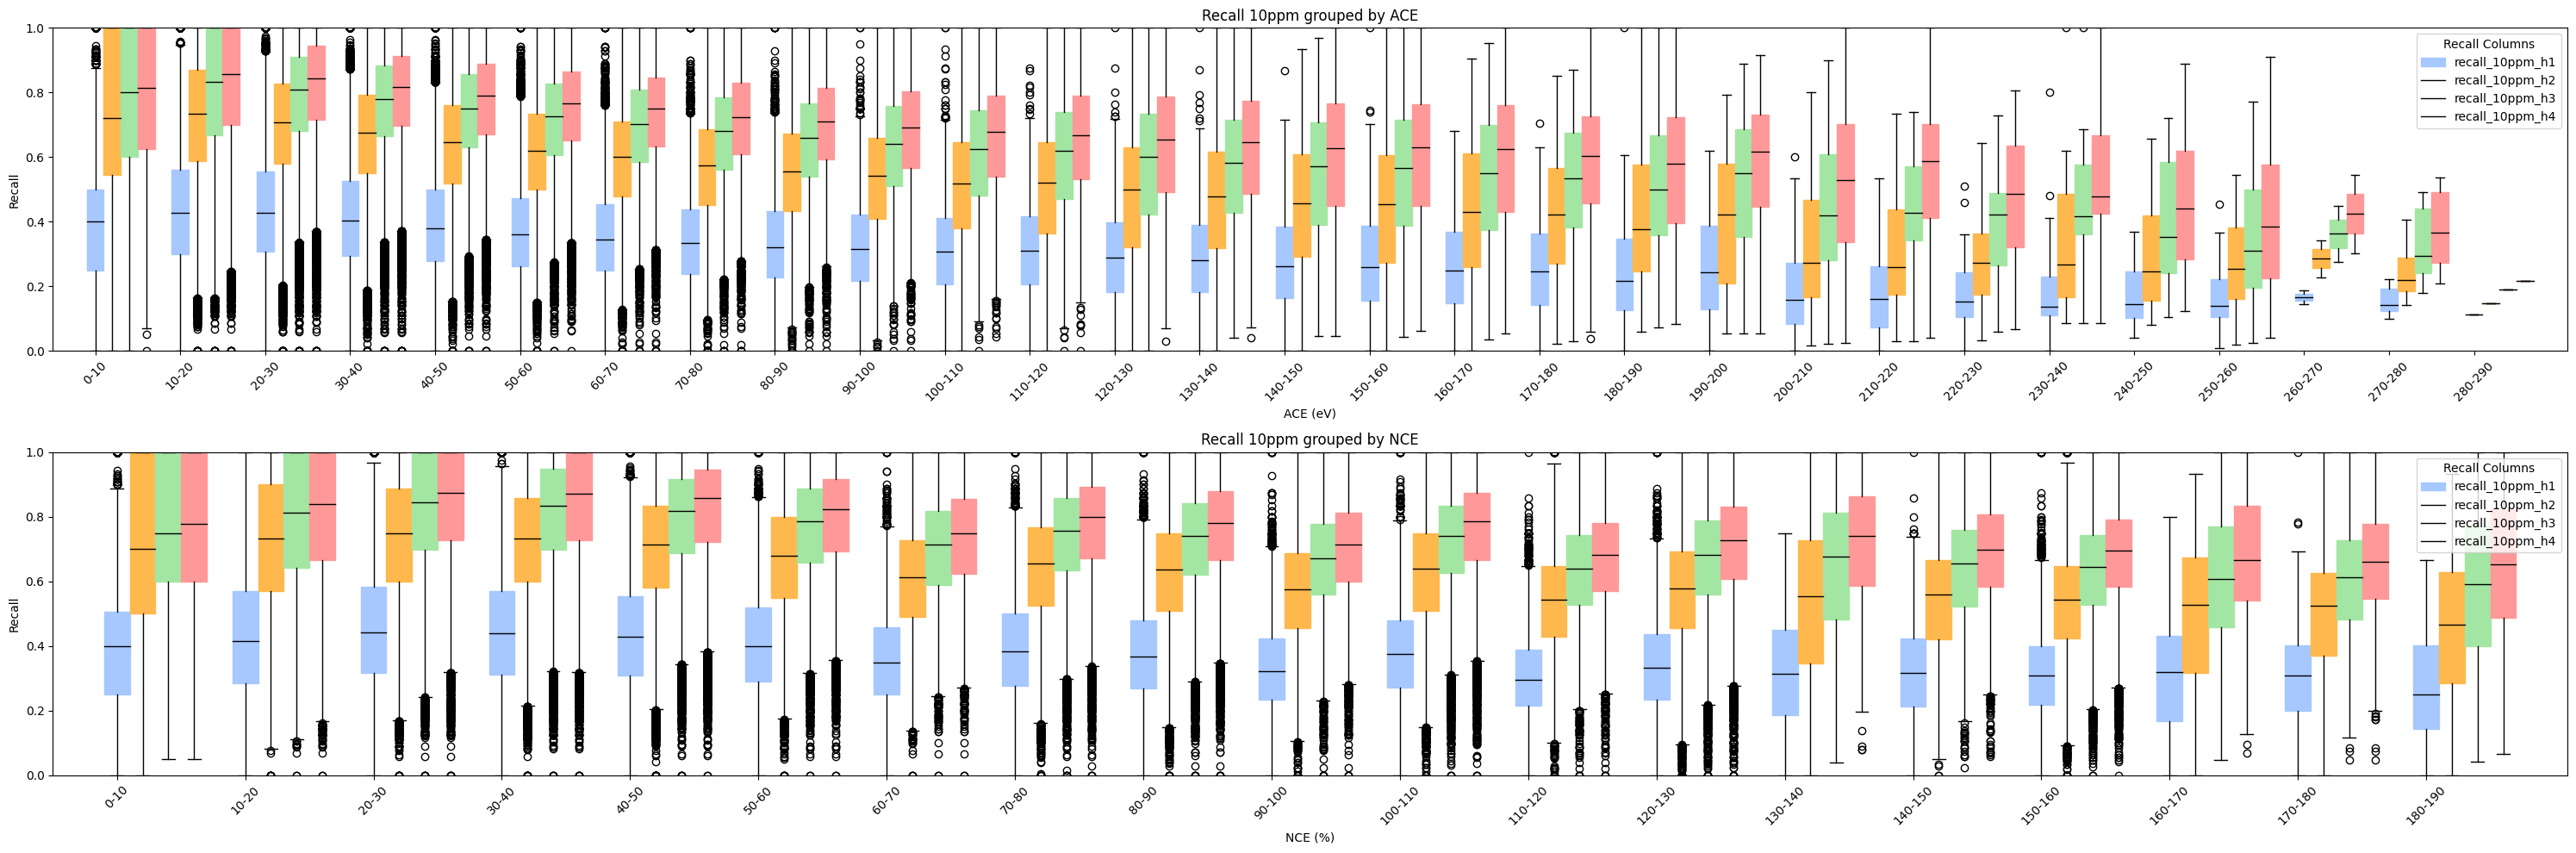

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']

# Define ACE and NCE bins
ace_bin_size = 10
nce_bin_size = 10
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a wider figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(30, 10))  # Increased the width
axes = axes.flatten()

# Lighter color choices (lighter shades of blue, orange, green, and red)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot box plots for each recall column grouped by ACE
ax = axes[0]
for i, col in enumerate(recall_columns):
    # Group by ACE bins and extract the corresponding values for boxplot
    ace_labels = pd.cut(selected_df['ace'], ace_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[ace_labels == interval][col] for interval in ace_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(ace_bins) - 1))
ax.set_xticklabels([f'{int(ace_bins[i])}-{int(ace_bins[i + 1])}' for i in range(len(ace_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot box plots for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    # Group by NCE bins and extract the corresponding values for boxplot
    nce_labels = pd.cut(selected_df['nce'], nce_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[nce_labels == interval][col] for interval in nce_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(nce_bins) - 1))
ax.set_xticklabels([f'{int(nce_bins[i])}-{int(nce_bins[i + 1])}' for i in range(len(nce_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()